In [1]:
import pandas as pd
import numpy as np
import seaborn as sns # a ploting library based on matplotlib
import matplotlib.pyplot as plt

# Preprocessing
removing or replacing the Null values

In [2]:
df = pd.read_csv("../data/raw/H2.csv", na_values=['NULL'], skipinitialspace=True)

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
IsCanceled,79330.0,NaN,NaN,NaN,0.41727,0.493111,0.0,0.0,0.0,1.0,1.0
LeadTime,79330.0,NaN,NaN,NaN,109.735724,110.948526,0.0,23.0,74.0,163.0,629.0
ArrivalDateYear,79330.0,NaN,NaN,NaN,2016.174285,0.699181,2015.0,2016.0,2016.0,2017.0,2017.0
ArrivalDateMonth,79330,12,August,8983,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ArrivalDateWeekNumber,79330.0,NaN,NaN,NaN,27.177449,13.398523,1.0,17.0,27.0,38.0,53.0
ArrivalDateDayOfMonth,79330.0,NaN,NaN,NaN,15.786625,8.728451,1.0,8.0,16.0,23.0,31.0
StaysInWeekendNights,79330.0,NaN,NaN,NaN,0.795185,0.885026,0.0,0.0,1.0,2.0,16.0
StaysInWeekNights,79330.0,NaN,NaN,NaN,2.182957,1.456416,0.0,1.0,2.0,3.0,41.0
Adults,79330.0,NaN,NaN,NaN,1.850977,0.509292,0.0,2.0,2.0,2.0,4.0
Children,79326.0,NaN,NaN,NaN,0.09137,0.372177,0.0,0.0,0.0,0.0,3.0


In [4]:
for c in df.select_dtypes(include=[str,'object']):
    print(c,df[c].isin(['NULL','NA','Undefined','','NaN']).sum())

ArrivalDateMonth 0
Meal 0
Country 0
MarketSegment 2
DistributionChannel 4
ReservedRoomType 0
AssignedRoomType 0
DepositType 0
CustomerType 0
ReservationStatus 0
ReservationStatusDate 0


### Fixing MarketSegment

In [5]:
df["MarketSegment"].unique()

<StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',     'Undefined',      'Aviation']
Length: 8, dtype: str

In [6]:
df[df["MarketSegment"] == 'Undefined']

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
540,1,2,2015,August,32,3,1,0,2,NaN,...,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
619,1,1,2015,August,32,5,0,2,3,NaN,...,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04


In [7]:
df = df[df["MarketSegment"] != "Undefined"]

In [8]:
df["MarketSegment"].unique()

<StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',      'Aviation']
Length: 7, dtype: str

### fixing DistributionChannel

In [9]:
df["DistributionChannel"].unique()

<StringArray>
['TA/TO', 'Direct', 'Corporate', 'Undefined', 'GDS']
Length: 5, dtype: str

In [10]:
df[df["DistributionChannel"].isin(['NULL','NA','Undefined',''])]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
607,1,1,2015,August,32,5,0,2,2,NaN,...,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
1100,1,8,2015,August,33,13,2,5,2,NaN,...,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [11]:
df = df[df["DistributionChannel"] != "Undefined"]

In [12]:
df["DistributionChannel"].unique()

<StringArray>
['TA/TO', 'Direct', 'Corporate', 'GDS']
Length: 4, dtype: str

---

In [13]:
df_string_columns = df.select_dtypes(include=[str,'object'])

In [14]:
df_string_columns.head()

,ArrivalDateMonth,Meal,Country,MarketSegment,DistributionChannel,ReservedRoomType,AssignedRoomType,DepositType,CustomerType,ReservationStatus,ReservationStatusDate
0,July,HB,PRT,Offline TA/TO,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-07-03
1,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-07-01
2,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-04-30
3,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-06-23
4,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-04-02


In [15]:
for c in df_string_columns.columns:
    print(c, df_string_columns[c].unique())

ArrivalDateMonth <StringArray>
[     'July',    'August', 'September',   'October',  'November',  'December',
   'January',  'February',     'March',     'April',       'May',      'June']
Length: 12, dtype: str
Meal <StringArray>
['HB       ', 'BB       ', 'SC       ', 'FB       ']
Length: 4, dtype: str
Country <StringArray>
['PRT', 'ITA', 'ESP', 'DEU', 'FRA', 'NLD', 'GBR', 'ROU', 'BRA', 'SWE',
 ...
 'SUR', 'MRT', 'CAF', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO', 'COM']
Length: 167, dtype: str
MarketSegment <StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',      'Aviation']
Length: 7, dtype: str
DistributionChannel <StringArray>
['TA/TO', 'Direct', 'Corporate', 'GDS']
Length: 4, dtype: str
ReservedRoomType <StringArray>
['A               ', 'B               ', 'D               ',
 'F               ', 'E               ', 'G               ',
 'C               ', 'P               ']
Length: 8, dtype: str
AssignedRoomType <

In [16]:
df["Company"].unique()

array([ nan,  40.,  45.,  38.,   9.,  47.,  49.,  51.,  48.,  62.,  67.,
        68.,  84.,  65.,  91.,  37.,   8.,  14., 174., 207., 179., 209.,
       219.,  72., 221., 227., 153., 186., 218.,  78., 253., 202., 216.,
       275., 277., 233., 280., 309., 321., 331.,  93., 316.,  85., 107.,
       350., 279., 334., 348., 405., 366., 365., 407., 242., 435., 150.,
        73., 428., 385., 418., 197., 409., 450., 452., 169., 466.,  43.,
       115., 465., 329.,  46.,  76.,  96., 358., 100., 108., 110.,  81.,
       120., 116., 105., 101., 122.,  11., 135., 137., 139., 144., 142.,
       127., 130., 143., 148., 140., 149., 163., 160., 180., 238., 183.,
       222., 203., 185., 217., 215., 193., 213., 224., 237., 230., 234.,
        35., 246., 245., 251., 255., 158., 258., 259., 260., 263., 411.,
       254., 272., 257., 271.,  18., 106., 210., 273., 278.,  71., 284.,
       292., 282., 301., 305., 307., 293., 264., 311., 304., 308., 313.,
       288., 312., 317., 320., 314., 332., 333., 34

In [17]:
df["Company"].isnull().sum()

np.int64(75637)

In [18]:
df['Country'].isnull().sum()

np.int64(24)

In [19]:
df[df['Country'].isnull()]['Country']

4831     NaN
4832     NaN
4833     NaN
4834     NaN
4835     NaN
4836     NaN
4837     NaN
4838     NaN
4839     NaN
4841     NaN
4842     NaN
4843     NaN
4844     NaN
4845     NaN
20591    NaN
21184    NaN
21185    NaN
21189    NaN
25847    NaN
25848    NaN
25849    NaN
25850    NaN
40770    NaN
61428    NaN
Name: Country, dtype: str

In [20]:
df["Country"] = df["Country"].fillna("Unknown")

In [21]:
df['Country'].isnull().sum()

np.int64(0)

In [22]:
df["Agent"].isnull().sum()

np.int64(8129)

In [23]:
df["Agent"].unique()

array([  6.,   9.,   1.,   8.,  13.,  11.,   7.,  15.,  nan,  27.,  14.,
        22.,  17.,  10.,  28.,  42.,   3.,  20.,  19.,  40.,  45.,  34.,
        37.,  57.,  61.,  16.,  39.,  21.,  24.,  69.,  41.,  50.,  30.,
        54.,  52.,  12.,  44.,  26.,  64.,  31.,  29.,  83.,  32.,  63.,
        66.,  60.,  55.,  56.,  89., 159., 155.,  38.,  91.,  87., 118.,
        86., 134.,  85.,  94., 210., 214., 129., 179., 138., 174., 154.,
       170., 182., 153.,  93., 151., 119.,  35., 168.,   2., 147., 195.,
       173.,  58.,  53., 128., 133.,  79., 152., 235., 192.,   5., 171.,
       191., 187., 236., 162., 215., 270., 157., 281., 177., 287., 240.,
       132., 331., 234.,  98.,  77., 103., 107., 262., 355., 220., 104.,
       330., 326., 121., 254., 205., 378.,  23., 296., 290., 229., 390.,
        33., 286.,  47., 276., 425., 315., 484., 323., 403., 219., 394.,
       509., 111., 423.,   4.,  71.,  78.,  72.,  75.,  70.,  82.,  81.,
        74.,  92.,  99.,  90.,  95., 112., 117., 10

In [24]:
df.isnull().sum()

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           0
Babies                             0
Meal                               0
Country                            0
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           8129
Company                        75637
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

### Checking for Anomalies

#### removing rows where total guests == 0
 this also removes any row with children/babies but no adult, which is ofcourse invalid

In [25]:
unaccompanied = df[(df["Adults"] == 0) & ((df["Children"] > 0) | (df["Babies"] > 0))]
print(len(unaccompanied))

223


In [26]:
df = df[df["Adults"] > 0]

In [27]:
unaccompanied = df[(df["Adults"] == 0) & ((df["Children"] > 0) | (df["Babies"] > 0))]
print(len(unaccompanied))

0


In [28]:
df["TotalGuests"] = df["Adults"] + df["Children"] + df["Babies"]

In [29]:
df[df["TotalGuests"] == 0]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,TotalGuests


In [30]:
df["IsFamily"] = (
    (df["Adults"] > 0) & ((df["Children"] + df["Babies"]) > 0)
).astype(int)

print(df["IsFamily"].value_counts())

IsFamily
0    73756
1     5180
Name: count, dtype: int64


In [31]:
df["Children"].unique()

array([0., 1., 2., 3.])

## Visuals and Plots

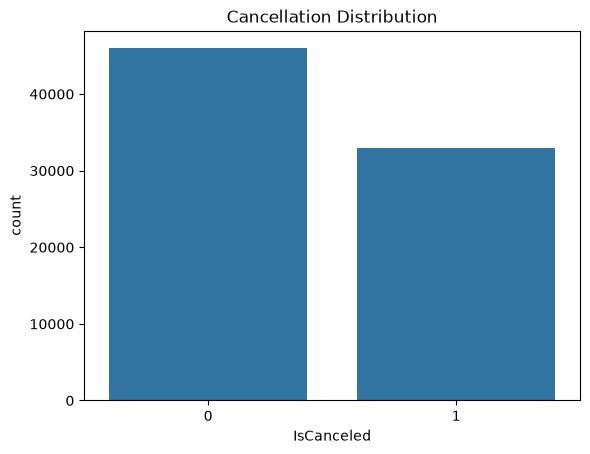

In [32]:
sns.countplot(data=df,x="IsCanceled") #creates a countplot(essentially a histogram) to using the data in df spicifically the column IsCanceled.
plt.title("Cancellation Distribution")
plt.show()

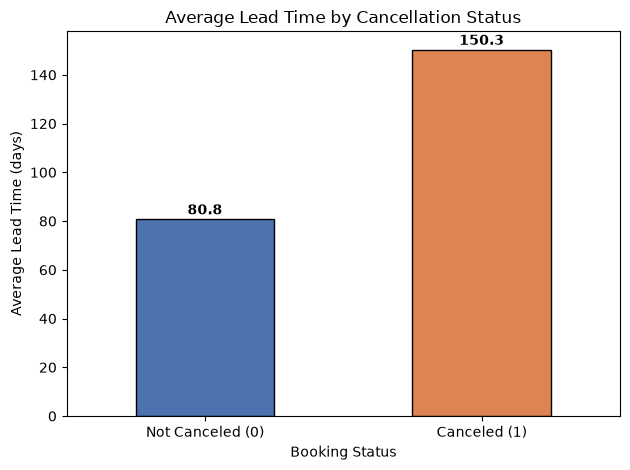

In [33]:
import matplotlib.pyplot as plt

avg_lead = df.groupby("IsCanceled")["LeadTime"].mean()

ax = avg_lead.plot(kind="bar", color=["#4C72B0", "#DD8452"], edgecolor="black")
ax.set_xticklabels(["Not Canceled (0)", "Canceled (1)"], rotation=0)
ax.set_xlabel("Booking Status")
ax.set_ylabel("Average Lead Time (days)")
ax.set_title("Average Lead Time by Cancellation Status")

# Show the value on top of each bar
for i, v in enumerate(avg_lead):
    ax.text(i, v + 2, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [34]:
sns.set_theme(style="whitegrid")

def cancel_rate_bar(col, title, order=None, min_count=0):
    counts = df[col].value_counts()
    keep = counts[counts >= min_count].index
    rates = df[df[col].isin(keep)].groupby(col)["IsCanceled"].mean()
    if order is not None:
        rates = rates.reindex([o for o in order if o in rates.index])
    else:
        rates = rates.sort_values(ascending=False)
    ax = rates.plot(kind="bar", color="#4C72B0", edgecolor="black")
    ax.set_ylabel("Cancellation Rate")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    for i, v in enumerate(rates):
        ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

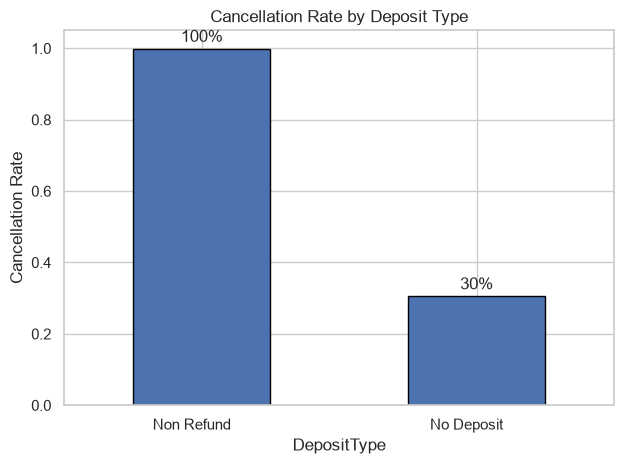

In [35]:
cancel_rate_bar("DepositType", "Cancellation Rate by Deposit Type", min_count=100)

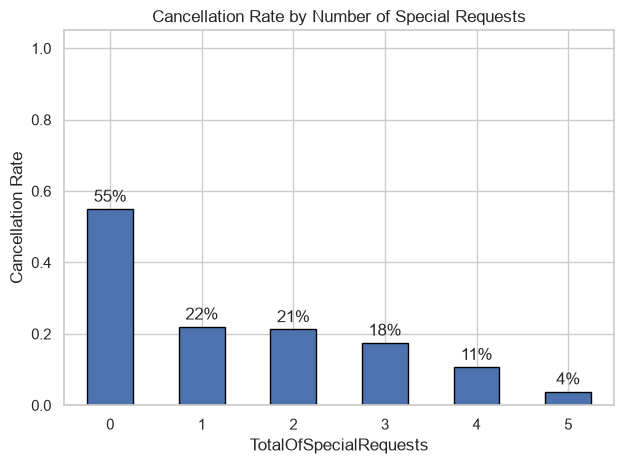

In [36]:
cancel_rate_bar("TotalOfSpecialRequests", "Cancellation Rate by Number of Special Requests")

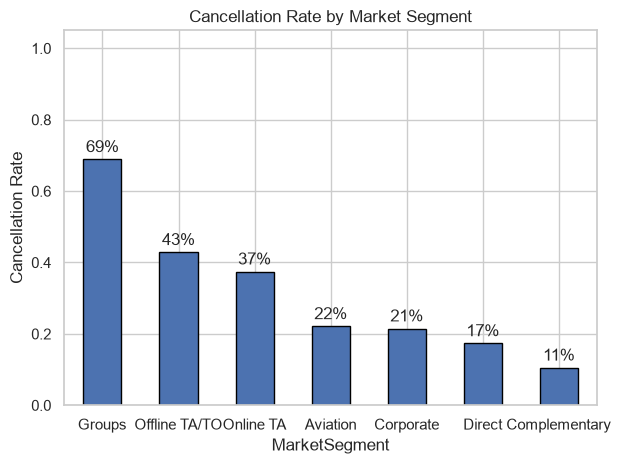

In [37]:
cancel_rate_bar("MarketSegment", "Cancellation Rate by Market Segment", min_count=100)

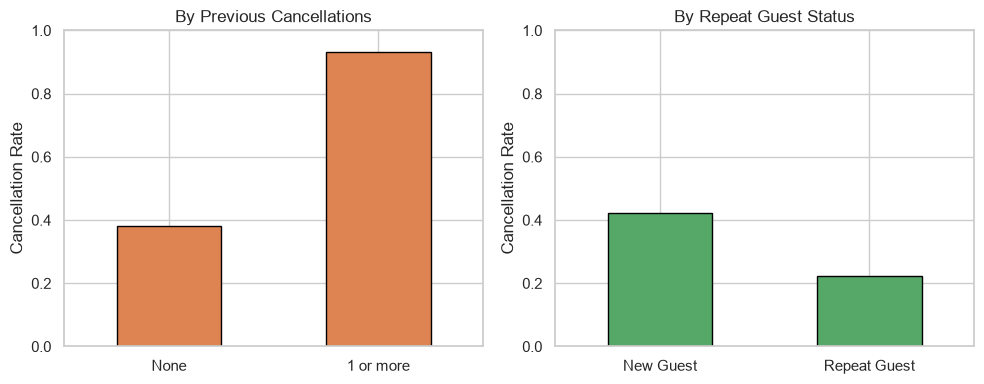

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

prev = df.groupby(df["PreviousCancellations"] > 0)["IsCanceled"].mean()
prev.index = ["None", "1 or more"]
prev.plot(kind="bar", ax=axes[0], color="#DD8452", edgecolor="black")
axes[0].set_title("By Previous Cancellations")

rep = df.groupby("IsRepeatedGuest")["IsCanceled"].mean()
rep.index = ["New Guest", "Repeat Guest"]
rep.plot(kind="bar", ax=axes[1], color="#55A868", edgecolor="black")
axes[1].set_title("By Repeat Guest Status")

for ax in axes:
    ax.set_ylabel("Cancellation Rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

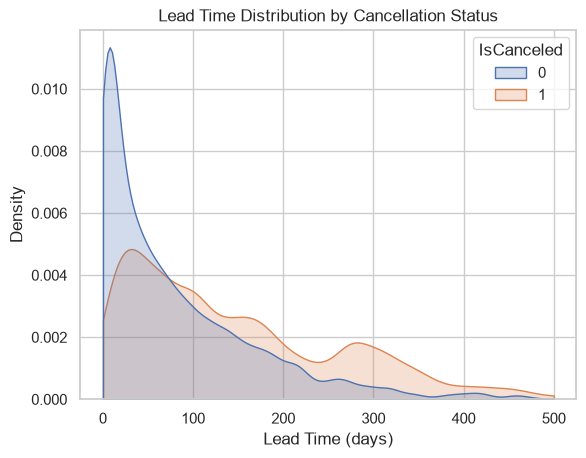

In [39]:
sns.kdeplot(data=df, x="LeadTime", hue="IsCanceled", common_norm=False, fill=True, clip=(0, 500))
plt.title("Lead Time Distribution by Cancellation Status")
plt.xlabel("Lead Time (days)")
plt.show()

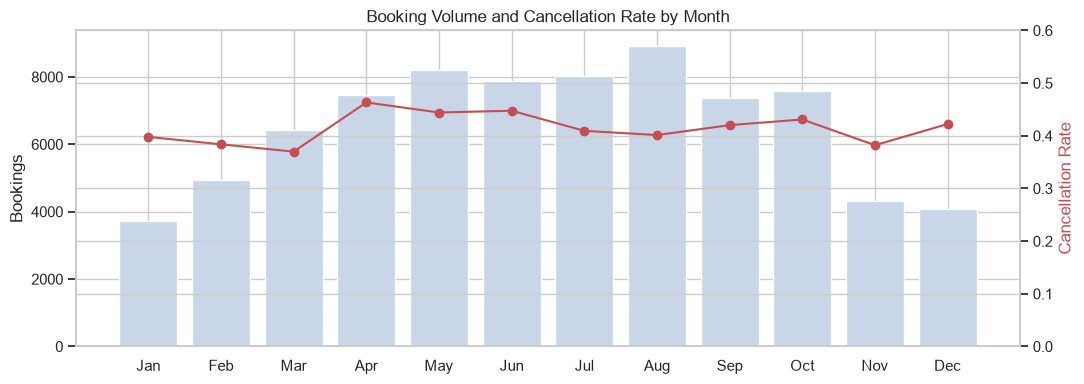

In [40]:
months = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]
monthly = df.groupby("ArrivalDateMonth").agg(
    bookings=("IsCanceled", "size"), cancel_rate=("IsCanceled", "mean")
).reindex(months)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly.index.str[:3], monthly["bookings"], color="#C9D6E8")
ax1.set_ylabel("Bookings")
ax2 = ax1.twinx()
ax2.plot(monthly.index.str[:3], monthly["cancel_rate"], color="#C44E52", marker="o")
ax2.set_ylabel("Cancellation Rate", color="#C44E52")
ax2.set_ylim(0, 0.6)
plt.title("Booking Volume and Cancellation Rate by Month")
plt.tight_layout()
plt.show()

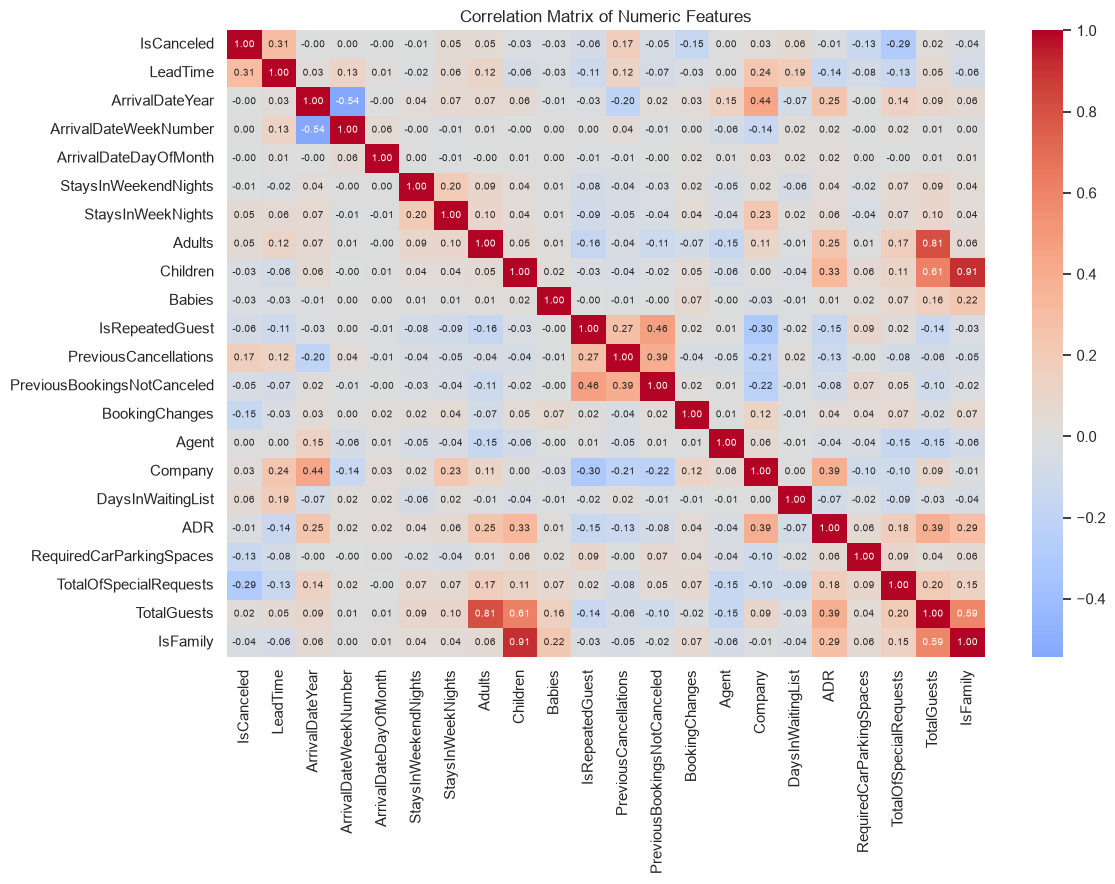

In [41]:
num = df.select_dtypes("number")
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

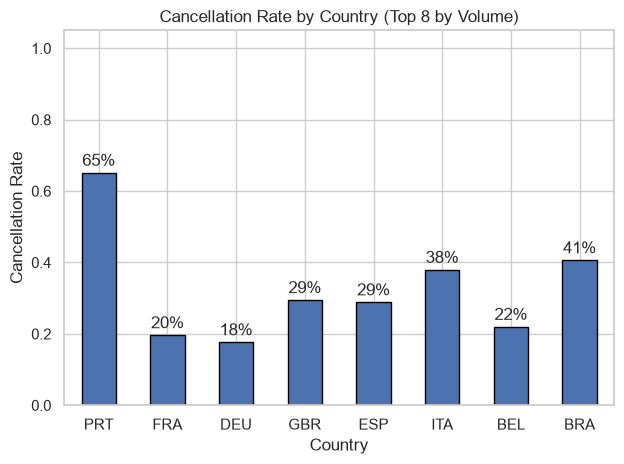

In [42]:
top = df["Country"].value_counts().head(8).index
cancel_rate_bar("Country", "Cancellation Rate by Country (Top 8 by Volume)", order=list(top))

In [43]:
print("Current shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum().to_string())

print("\nExact duplicates:")
print(df.duplicated().sum())

Current shape: (78936, 33)

Missing values:
IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           0
Babies                             0
Meal                               0
Country                            0
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           8061
Company                        75272
DaysInWaitingList                  0
CustomerType                   

In [44]:
# Baseline features: booking lead time, stay length, and party composition
features = [
    "LeadTime",
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "Adults",
    "Children",
    "Babies",
]

X = df[features].copy()

print("Feature matrix:", X.shape)
print("\nMissing values:")
print(X.isna().sum())

print("\nNegative values:")
print((X < 0).sum())

print("\nFeature summary:")
display(X.describe().T)

Feature matrix: (78936, 6)

Missing values:
LeadTime                0
StaysInWeekendNights    0
StaysInWeekNights       0
Adults                  0
Children                0
Babies                  0
dtype: int64

Negative values:
LeadTime                0
StaysInWeekendNights    0
StaysInWeekNights       0
Adults                  0
Children                0
Babies                  0
dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
LeadTime,78936.0,109.847471,111.001185,0.0,23.0,74.0,164.0,629.0
StaysInWeekendNights,78936.0,0.793592,0.878550,0.0,0.0,1.0,2.0,14.0
StaysInWeekNights,78936.0,2.179690,1.432713,0.0,1.0,2.0,3.0,34.0
Adults,78936.0,1.860102,0.493604,1.0,2.0,2.0,2.0,4.0
Children,78936.0,0.086082,0.358238,0.0,0.0,0.0,0.0,3.0
Babies,78936.0,0.004928,0.084310,0.0,0.0,0.0,0.0,10.0


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("scaler", StandardScaler()),
])

X_scaled = preprocessor.fit_transform(X)

print("Prepared shape:", X_scaled.shape)
print("All values finite:", np.isfinite(X_scaled).all())

display(
    pd.DataFrame(X_scaled, columns=features, index=X.index)
    .agg(["mean", "std"])
    .round(3)
)

Prepared shape: (78936, 6)
All values finite: True


,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies
mean,0.0,0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [46]:
from sklearn.cluster import DBSCAN
from time import perf_counter

# Compress identical feature rows while preserving their counts
X_unique, inverse, counts = np.unique(
    X_scaled,
    axis=0,
    return_inverse=True,
    return_counts=True,
)

print("Original rows:", len(X_scaled))
print("Unique feature rows:", len(X_unique))

# Initial baseline settings, before tuning
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5,
    algorithm="ball_tree",
    n_jobs=1,
)

start = perf_counter()
dbscan.fit(X_unique, sample_weight=counts)

# Restore a cluster label for every original row
labels = dbscan.labels_[inverse]

n_clusters = len(set(labels) - {-1})
noise_count = int((labels == -1).sum())

print("Clusters:", n_clusters)
print("Noise points:", noise_count)
print(f"Noise percentage: {noise_count / len(labels):.2%}")
print(f"Fit time: {perf_counter() - start:.2f} seconds")

display(
    pd.Series(labels, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Bookings")
    .to_frame()
)

Original rows: 78936
Unique feature rows: 13206
Clusters: 186
Noise points: 700
Noise percentage: 0.89%
Fit time: 0.22 seconds


,Bookings
Cluster,
-1,700
0,90
1,141
2,7
3,6
...,...
181,15
182,19
183,24


In [47]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Evaluate clustered bookings only; report noise separately
mask = labels != -1
X_eval = X_scaled[mask]
labels_eval = labels[mask]

n_labels = len(np.unique(labels_eval))

if 2 <= n_labels < len(labels_eval):
    # Fixed random sample to keep silhouette computation manageable
    rng = np.random.default_rng(42)
    idx = rng.choice(
        len(X_eval),
        size=min(5000, len(X_eval)),
        replace=False,
    )

    sampled_labels = labels_eval[idx]

    if 2 <= len(np.unique(sampled_labels)) < len(idx):
        silhouette = silhouette_score(X_eval[idx], sampled_labels)
        print(f"Silhouette (random sample): {silhouette:.4f}")
        print("Clusters represented in sample:",
              len(np.unique(sampled_labels)))
    else:
        print("Silhouette: undefined for this sample")

    db_index = davies_bouldin_score(X_eval, labels_eval)
    print(f"Davies-Bouldin (all non-noise rows): {db_index:.4f}")
else:
    print("Metrics undefined: need 2 to n_samples-1 clusters")

sizes = pd.Series(labels_eval).value_counts()

print("\nCluster size summary:")
print(sizes.describe().to_string())
print("\nLargest 10 clusters:")
print(sizes.head(10).to_string())

Silhouette (random sample): 0.1880
Clusters represented in sample: 132
Davies-Bouldin (all non-noise rows): 1.1341

Cluster size summary:
count      186.000000
mean       420.623656
std       1200.659741
min          3.000000
25%          9.250000
50%         31.000000
75%        198.750000
max      10017.000000

Largest 10 clusters:
15    10017
21     6281
6      5484
45     5060
67     3795
40     3776
4      3767
72     3753
13     3126
51     2995


In [48]:
# Preserve original feature values for interpretation
cluster_profiles = X.copy()
cluster_profiles["Cluster"] = labels

sizes = cluster_profiles.groupby("Cluster").size().rename("Bookings")
means = cluster_profiles.groupby("Cluster")[features].mean()

profiles = sizes.to_frame().join(means)
profiles["Percentage"] = 100 * profiles["Bookings"] / len(X)

print("Largest 10 clusters — mean feature values:")
display(
    profiles.drop(index=-1, errors="ignore")
    .sort_values("Bookings", ascending=False)
    .head(10)
    .round(2)
)

print("Noise profile:")
display(profiles.loc[profiles.index == -1].round(2))

Largest 10 clusters — mean feature values:


,Bookings,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Percentage
Cluster,,,,,,,,
15,10017,177.60,0.0,2.0,2.0,0.0,0.0,12.69
21,6281,119.33,0.0,3.0,2.0,0.0,0.0,7.96
6,5484,76.55,0.0,1.0,2.0,0.0,0.0,6.95
45,5060,134.12,1.0,2.0,2.0,0.0,0.0,6.41
67,3795,129.03,2.0,1.0,2.0,0.0,0.0,4.81
40,3776,138.33,1.0,1.0,2.0,0.0,0.0,4.78
4,3767,45.76,0.0,1.0,1.0,0.0,0.0,4.77
72,3753,104.45,2.0,2.0,2.0,0.0,0.0,4.75
13,3126,90.32,0.0,2.0,1.0,0.0,0.0,3.96


Noise profile:


,Bookings,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Percentage
Cluster,,,,,,,,
-1,700,122.57,2.46,6.12,2.0,0.87,0.19,0.89


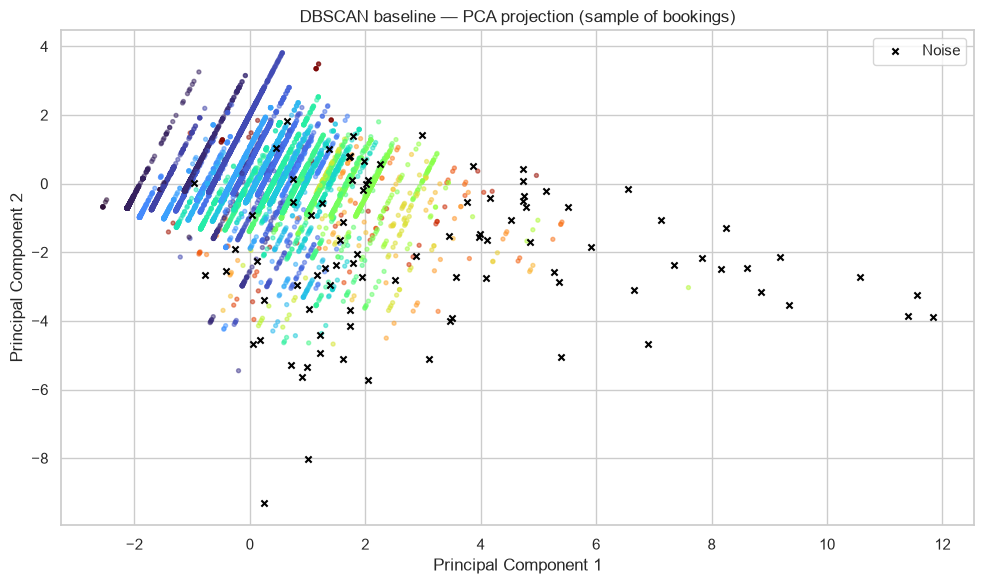

Explained variance per component: [0.217  0.1831]
Total explained variance: 40.01%


In [49]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# Fixed random sample for a readable plot
rng = np.random.default_rng(42)
plot_idx = rng.choice(
    len(X_2d), size=min(10000, len(X_2d)), replace=False
)

points = X_2d[plot_idx]
plot_labels = labels[plot_idx]
noise = plot_labels == -1

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    points[~noise, 0],
    points[~noise, 1],
    c=plot_labels[~noise],
    cmap="turbo",
    s=8,
    alpha=0.5,
)

ax.scatter(
    points[noise, 0],
    points[noise, 1],
    color="black",
    marker="x",
    s=20,
    label="Noise",
)

ax.set(
    title="DBSCAN baseline — PCA projection (sample of bookings)",
    xlabel="Principal Component 1",
    ylabel="Principal Component 2",
)
ax.legend()
plt.tight_layout()
plt.show()

print("Explained variance per component:",
      pca.explained_variance_ratio_.round(4))
print(f"Total explained variance: "
      f"{pca.explained_variance_ratio_.sum():.2%}")

In [50]:
from pathlib import Path

# Locate the repository from either its root or notebooks folder
root = Path.cwd()
if not (root / "config.yaml").exists():
    root = root.parent

if not (root / "config.yaml").exists():
    raise FileNotFoundError("Could not locate the project root.")

tables_dir = root / "outputs" / "tables"
figures_dir = root / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

baseline_results = pd.DataFrame([{
    "model": "DBSCAN",
    "configuration": "baseline",
    "eps": dbscan.eps,
    "min_samples": dbscan.min_samples,
    "rows": len(X_scaled),
    "features": ", ".join(features),
    "clusters": n_clusters,
    "noise_points": noise_count,
    "noise_percentage": 100 * noise_count / len(labels),
    "silhouette_sample": silhouette,
    "silhouette_sample_size": len(idx),
    "silhouette_clusters_represented": len(np.unique(sampled_labels)),
    "evaluation_excludes_noise": True,
    "davies_bouldin": db_index,
    "pca_2d_explained_variance": pca.explained_variance_ratio_.sum(),
}])

baseline_results.to_csv(
    tables_dir / "dbscan_baseline_metrics.csv", index=False
)

profiles.to_csv(tables_dir / "dbscan_baseline_profiles.csv")

fig.savefig(
    figures_dir / "dbscan_baseline_pca.png",
    dpi=200,
    bbox_inches="tight",
)

print("Baseline metrics, cluster profiles, and PCA figure saved.")

Baseline metrics, cluster profiles, and PCA figure saved.


## DBSCAN Baseline — Preliminary Findings

- Input: 78,936 bookings and six numerical features.
- Features: LeadTime, StaysInWeekendNights, StaysInWeekNights,
  Adults, Children, and Babies.
- Preprocessing: existing notebook cleaning followed by StandardScaler.
- No cancellation outcomes or reservation-status fields were used as inputs.
- Identical feature rows were compressed using their counts as sample weights;
  labels were then mapped back to all bookings.

### Configuration and Results

- eps: 0.5
- min_samples: 5
- Clusters: 186
- Noise: 700 bookings (0.89%)
- Silhouette: 0.1880 on a fixed random sample of 5,000 non-noise bookings.
  The sample represented 132 of the 186 clusters.
- Davies–Bouldin: 1.1341 on all non-noise bookings.
- Two-component PCA explained variance: 40.01%.
  PCA was used for visualization only.

### Interpretation and Limitations

The largest clusters mainly distinguish party composition and exact
weekday/weekend stay lengths. Noise bookings have longer average stays
and higher average child and baby counts.

The silhouette result suggests limited separation in the sampled data.
The large number of small clusters requires further investigation.
The PCA plot shows only part of the feature variation.

These are baseline results, not an optimized final model.
Feature selection and preprocessing must be coordinated with the other
clustering experiments for a fair comparison.

### Remaining Work

- Document and review inherited cleaning rules and duplicate handling.
- Move reusable preprocessing and DBSCAN code into project modules.
- Compare baseline and systematically tuned configurations.